# Pipeline (Flujo de Análisis)

## Estadística Descriptiva

Analizar y describir un conjunto de datos

### 1. Característización

> Características:

1. **Informativas** - Características que informan un resultado
2. **Respuestas** - Características que tienen un costo conocerse

### 2. Estadística

> Individual

1. **Categóricas** - Soporte (número observaciones) de cada categoría y la Proporción o porcentaje de cada categoría.
2. **Numéricas** - Media (promedio), Desviación estándar, Mínimo, Cuartil 1 ($Q_1$ al $25\%$ ordenado), Cuartil 2 o Mediana ($Q_2$ al $50\%$ ordenado), Cuartil 3 ($Q_3$ al $75\%$ ordenado), Máximo

> Contraste (cruzada) contra una respuesta Categórica

1. **Categórica** - El contraste entre categórica contra otra categórica, por lo que calculamos los soportes y las proporciones para cada combinación (categorías de la variable informativa y categorías de la respuesta)
2. **Numérica** - El contraste entre numérica contra categórica, por lo que determinar la estadística de la numérica frente a la estadística de la categórica

> Contraste (cruzada) contra una respuesta Numérica

1. **Categórica** - El contraste entre categórica contra una numérica, por lo que para cada categórica calculamos la estadística de la numérica
2. **Numérica** - El contraste entre numérica y otra numérica, la correlación que existe entre ambas, y los grados de correlación entre sus cuartiles, quintiles, deciles o algún otro cuantil.

## 3. Visualización de datos

> Individual

1. **Categóricas** - Barras por cada categoría
2. **Numéricas** - Densidad y caja espacial

> Contraste (cruzada) para una respuesta categórica

1. **Categórica** - Mapa de color (calor)
2. **Numérico** - Densidad segmentada por la respuesta y las cajas segmentadas por la respuesta

> Contraste (cruzada) para una respuesta numérica

1. **Categórica** - Densidad segmentada por la respuesta y las cajas segmentadas por la respuesta
2. **Numérica** - Dispersión de puntos

In [1]:
import numpy
import pandas

from matplotlib import pyplot
import seaborn

In [7]:
titanic = pandas.read_csv("https://github.com/dragonnomada/pycien26/raw/refs/heads/main/conjuntos/titanic.csv")

titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [10]:
# Respuesta - Supervivencia (Categórica de 2 clases)
supervivencia = titanic["Survived"].map({
    1: "SOBREVIVE",
    0: "NO SOBREVIVE"
})

# Respuesta - Clase del pasajero (Numércica del 1 al 3)
clase_pasajero = titanic["Pclass"]

# Infomativa - Edad (Numérica del 0 al 90 aprox.)
edad = titanic["Age"].fillna(titanic["Age"].median()) # Imputación por la mediana

# Informativa - Sexo (Categórica de 2 clases)
sexo = titanic["Sex"].map({
    "male": "HOMBRE",
    "female": "MUJER"
}).fillna("DESCONOCIDO")

# Informativa - Familia (Numérica del 0 al 10)
familia = titanic["SibSp"] + titanic["Parch"]

# Informativa - Tarifa (Numérica del 0 al 14)
# * La tarifa tiene muchos puntos atípicos y necesitamos corregir por el logaritmo más 1
tarifa = titanic["Fare"].apply(numpy.log1p) # Transformación del logaritmo +1

# Informativa - Cabina (Categórica de 2 clases)
cabina = (~titanic["Cabin"].isna()).astype(int).map({
    1: "CON CABINA",
    0: "SIN CABINA"
})

#Informativa - Embarcación (Categórica de 3 clases)
embarcacion = titanic["Embarked"].map({
    "Q": "IRLANDA",
    "S": "LONDRES",
    "C": "FRANCIA"
})

In [19]:
supervivencia.name = "Supervivencia"
clase_pasajero.name = "Clase Pasajero"
edad.name = "Edad"
sexo.name = "Sexo"
familia.name = "Familia"
tarifa.name = "Tarifa"
cabina.name = "Cabina"
embarcacion.name = "Embarcacion"

Estadística individual

In [23]:
pandas.concat([
    supervivencia.value_counts(),
    supervivencia.value_counts(normalize=True),
], axis=1)

,count,proportion
Supervivencia,,
NO SOBREVIVE,549,0.616162
SOBREVIVE,342,0.383838


In [24]:
pandas.DataFrame(clase_pasajero.describe())

,Clase Pasajero
count,891.000000
mean,2.308642
std,0.836071
min,1.000000
25%,2.000000
50%,3.000000
75%,3.000000
max,3.000000


In [25]:
pandas.DataFrame(edad.describe())

,Edad
count,891.000000
mean,29.361582
std,13.019697
min,0.420000
25%,22.000000
50%,28.000000
75%,35.000000
max,80.000000


In [26]:
pandas.concat([
    sexo.value_counts(),
    sexo.value_counts(normalize=True),
], axis=1)

,count,proportion
Sexo,,
HOMBRE,577,0.647587
MUJER,314,0.352413


In [27]:
pandas.DataFrame(familia.describe())

,Familia
count,891.000000
mean,0.904602
std,1.613459
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,10.000000


In [28]:
pandas.DataFrame(tarifa.describe())

,Tarifa
count,891.000000
mean,2.962246
std,0.969048
min,0.000000
25%,2.187218
50%,2.737881
75%,3.465736
max,6.240917


In [29]:
pandas.concat([
    cabina.value_counts(),
    cabina.value_counts(normalize=True),
], axis=1)

,count,proportion
Cabina,,
SIN CABINA,687,0.771044
CON CABINA,204,0.228956


In [31]:
pandas.concat([
    embarcacion.value_counts(),
    embarcacion.value_counts(normalize=True),
], axis=1)

,count,proportion
Embarcacion,,
LONDRES,644,0.724409
FRANCIA,168,0.188976
IRLANDA,77,0.086614


Estadística de Contraste

In [35]:
pandas.DataFrame({
    "Supervivencia": supervivencia,
    "Edad": edad
}).groupby(["Supervivencia"]).describe()

Edad                                                    
               count       mean        std   min   25%   50%   75%   max
Supervivencia                                                           
NO SOBREVIVE   549.0  30.028233  12.499986  1.00  23.0  28.0  35.0  74.0
SOBREVIVE      342.0  28.291433  13.764425  0.42  21.0  28.0  35.0  80.0

In [38]:
pandas.DataFrame({
    "Supervivencia": supervivencia,
    "Sexo": sexo
}).groupby(["Supervivencia", "Sexo"]).size().unstack()

Sexo,HOMBRE,MUJER
Supervivencia,,
NO SOBREVIVE,468,81
SOBREVIVE,109,233


In [39]:
A = pandas.DataFrame({
    "Supervivencia": supervivencia,
    "Sexo": sexo
}).groupby(["Supervivencia", "Sexo"]).size().unstack()

A.divide(A.sum(axis=0), axis=1)

Sexo,HOMBRE,MUJER
Supervivencia,,
NO SOBREVIVE,0.811092,0.257962
SOBREVIVE,0.188908,0.742038


In [40]:
A.divide(A.sum(axis=1), axis=0)

Sexo,HOMBRE,MUJER
Supervivencia,,
NO SOBREVIVE,0.852459,0.147541
SOBREVIVE,0.318713,0.681287


In [41]:
pandas.DataFrame({
    "Supervivencia": supervivencia,
    "Familia": familia
}).groupby("Supervivencia").describe()

Familia                                              
                count      mean       std  min  25%  50%  75%   max
Supervivencia                                                      
NO SOBREVIVE    549.0  0.883424  1.830669  0.0  0.0  0.0  1.0  10.0
SOBREVIVE       342.0  0.938596  1.186076  0.0  0.0  1.0  2.0   6.0

In [42]:
pandas.DataFrame({
    "Supervivencia": supervivencia,
    "Tarifa": tarifa
}).groupby("Supervivencia").describe()

Tarifa                                                         \
               count      mean       std  min       25%       50%       75%   
Supervivencia                                                                 
NO SOBREVIVE   549.0  2.710095  0.869085  0.0  2.180892  2.442347  3.295837   
SOBREVIVE      342.0  3.367015  0.985096  0.0  2.600836  3.295837  4.060443   

                         
                    max  
Supervivencia            
NO SOBREVIVE   5.575949  
SOBREVIVE      6.240917

In [43]:
pandas.DataFrame({
    "Supervivencia": supervivencia,
    "Cabina": cabina
}).groupby(["Supervivencia", "Cabina"]).size().unstack()

Cabina,CON CABINA,SIN CABINA
Supervivencia,,
NO SOBREVIVE,68,481
SOBREVIVE,136,206


In [44]:
A = pandas.DataFrame({
    "Supervivencia": supervivencia,
    "Cabina": cabina
}).groupby(["Supervivencia", "Cabina"]).size().unstack()

A.divide(A.sum(axis=0), axis=1)

Cabina,CON CABINA,SIN CABINA
Supervivencia,,
NO SOBREVIVE,0.333333,0.700146
SOBREVIVE,0.666667,0.299854


In [45]:
A.divide(A.sum(axis=1), axis=0)

Cabina,CON CABINA,SIN CABINA
Supervivencia,,
NO SOBREVIVE,0.123862,0.876138
SOBREVIVE,0.397661,0.602339


In [46]:
pandas.DataFrame({
    "Supervivencia": supervivencia,
    "Embarcacion": embarcacion
}).groupby(["Supervivencia", "Embarcacion"]).size().unstack()

Embarcacion,FRANCIA,IRLANDA,LONDRES
Supervivencia,,,
NO SOBREVIVE,75,47,427
SOBREVIVE,93,30,217


In [47]:
A = pandas.DataFrame({
    "Supervivencia": supervivencia,
    "Embarcacion": embarcacion
}).groupby(["Supervivencia", "Embarcacion"]).size().unstack()

A.divide(A.sum(axis=0), axis=1)

Embarcacion,FRANCIA,IRLANDA,LONDRES
Supervivencia,,,
NO SOBREVIVE,0.446429,0.61039,0.663043
SOBREVIVE,0.553571,0.38961,0.336957


In [48]:
A.divide(A.sum(axis=1), axis=0)

Embarcacion,FRANCIA,IRLANDA,LONDRES
Supervivencia,,,
NO SOBREVIVE,0.136612,0.085610,0.777778
SOBREVIVE,0.273529,0.088235,0.638235


## Visualización

<Axes: xlabel='Supervivencia', ylabel='count'>

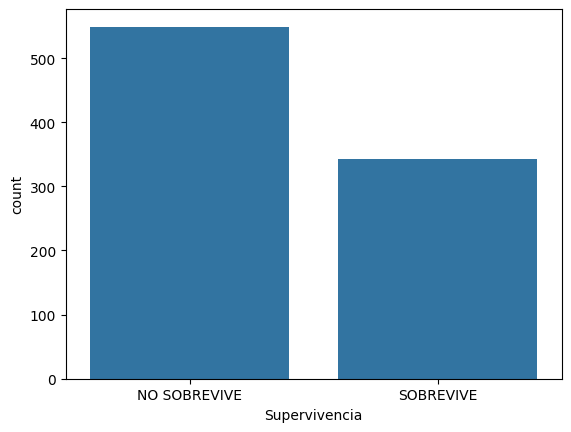

In [52]:
seaborn.barplot(supervivencia.value_counts())

Text(0.5, 0, '')

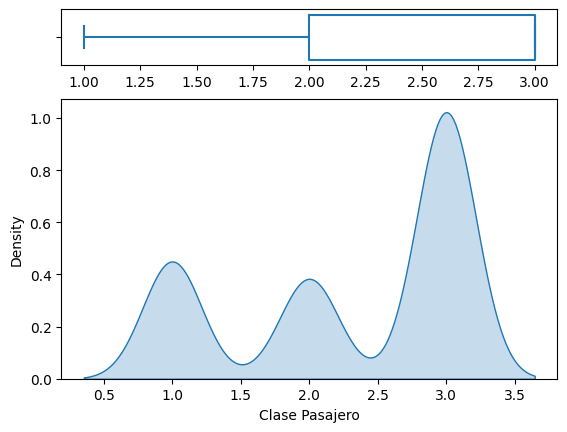

In [68]:
figure, axes = pyplot.subplots(2, 1, height_ratios=(1, 5))
seaborn.boxplot(x=clase_pasajero, fill=False, ax=axes[0])
seaborn.kdeplot(x=clase_pasajero, fill=True, ax=axes[1])
axes[0].set_xlabel(None)

Text(0.5, 0, '')

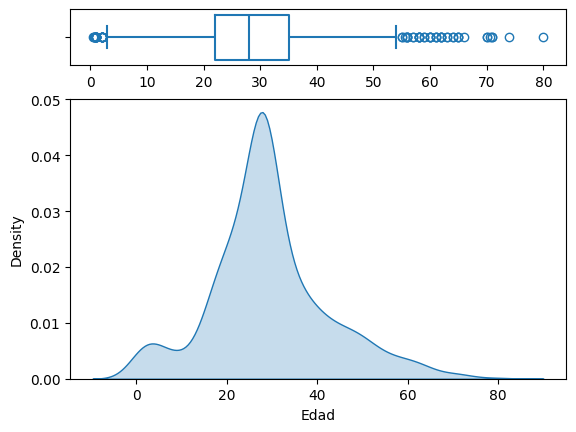

In [66]:
figure, axes = pyplot.subplots(2, 1, height_ratios=(1, 5))
seaborn.boxplot(x=edad, fill=False, ax=axes[0])
seaborn.kdeplot(x=edad, fill=True, ax=axes[1])
axes[0].set_xlabel(None)

<Axes: xlabel='Sexo', ylabel='count'>

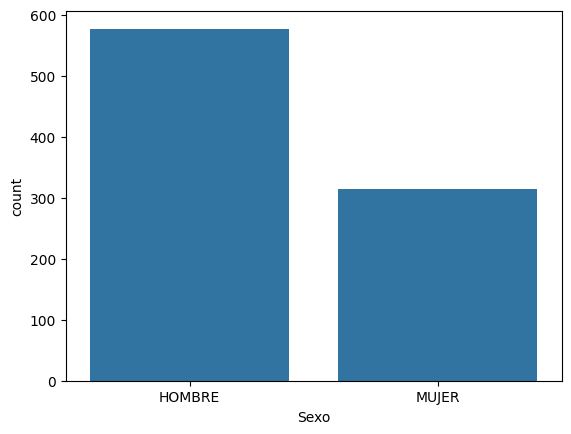

In [69]:
seaborn.barplot(sexo.value_counts())

Text(0.5, 0, '')

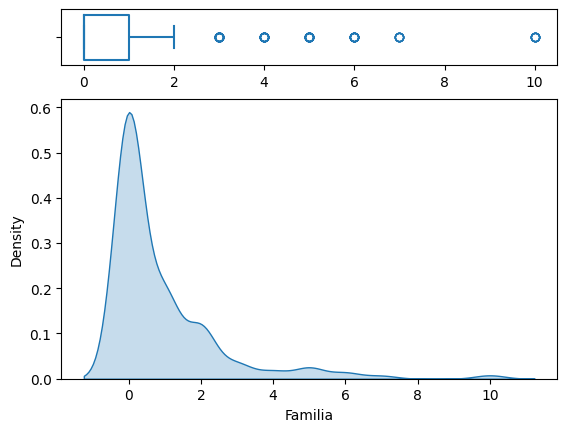

In [70]:
figure, axes = pyplot.subplots(2, 1, height_ratios=(1, 5))
seaborn.boxplot(x=familia, fill=False, ax=axes[0])
seaborn.kdeplot(x=familia, fill=True, ax=axes[1])
axes[0].set_xlabel(None)

Text(0.5, 0, '')

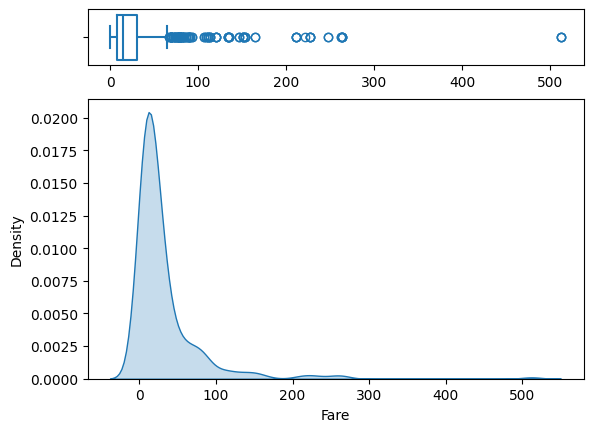

In [72]:
figure, axes = pyplot.subplots(2, 1, height_ratios=(1, 5))
seaborn.boxplot(x=titanic["Fare"], fill=False, ax=axes[0])
seaborn.kdeplot(x=titanic["Fare"], fill=True, ax=axes[1])
axes[0].set_xlabel(None)

Text(0.5, 0, '')

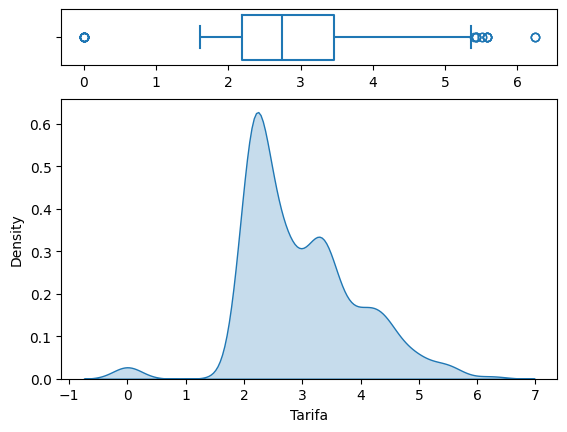

In [71]:
figure, axes = pyplot.subplots(2, 1, height_ratios=(1, 5))
seaborn.boxplot(x=tarifa, fill=False, ax=axes[0])
seaborn.kdeplot(x=tarifa, fill=True, ax=axes[1])
axes[0].set_xlabel(None)

<Axes: xlabel='Cabina', ylabel='count'>

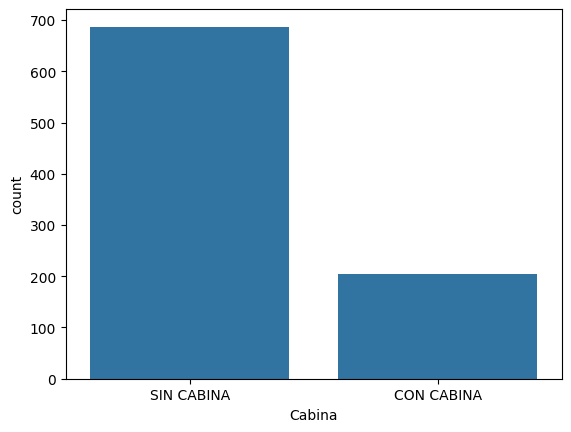

In [73]:
seaborn.barplot(cabina.value_counts())

<Axes: xlabel='Embarcacion', ylabel='count'>

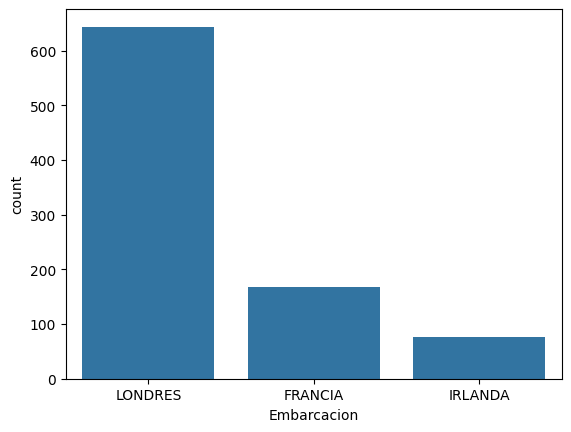

In [74]:
seaborn.barplot(embarcacion.value_counts())

Contraste contra Supervivencia (categórica)

<Axes: xlabel='Edad', ylabel='Density'>

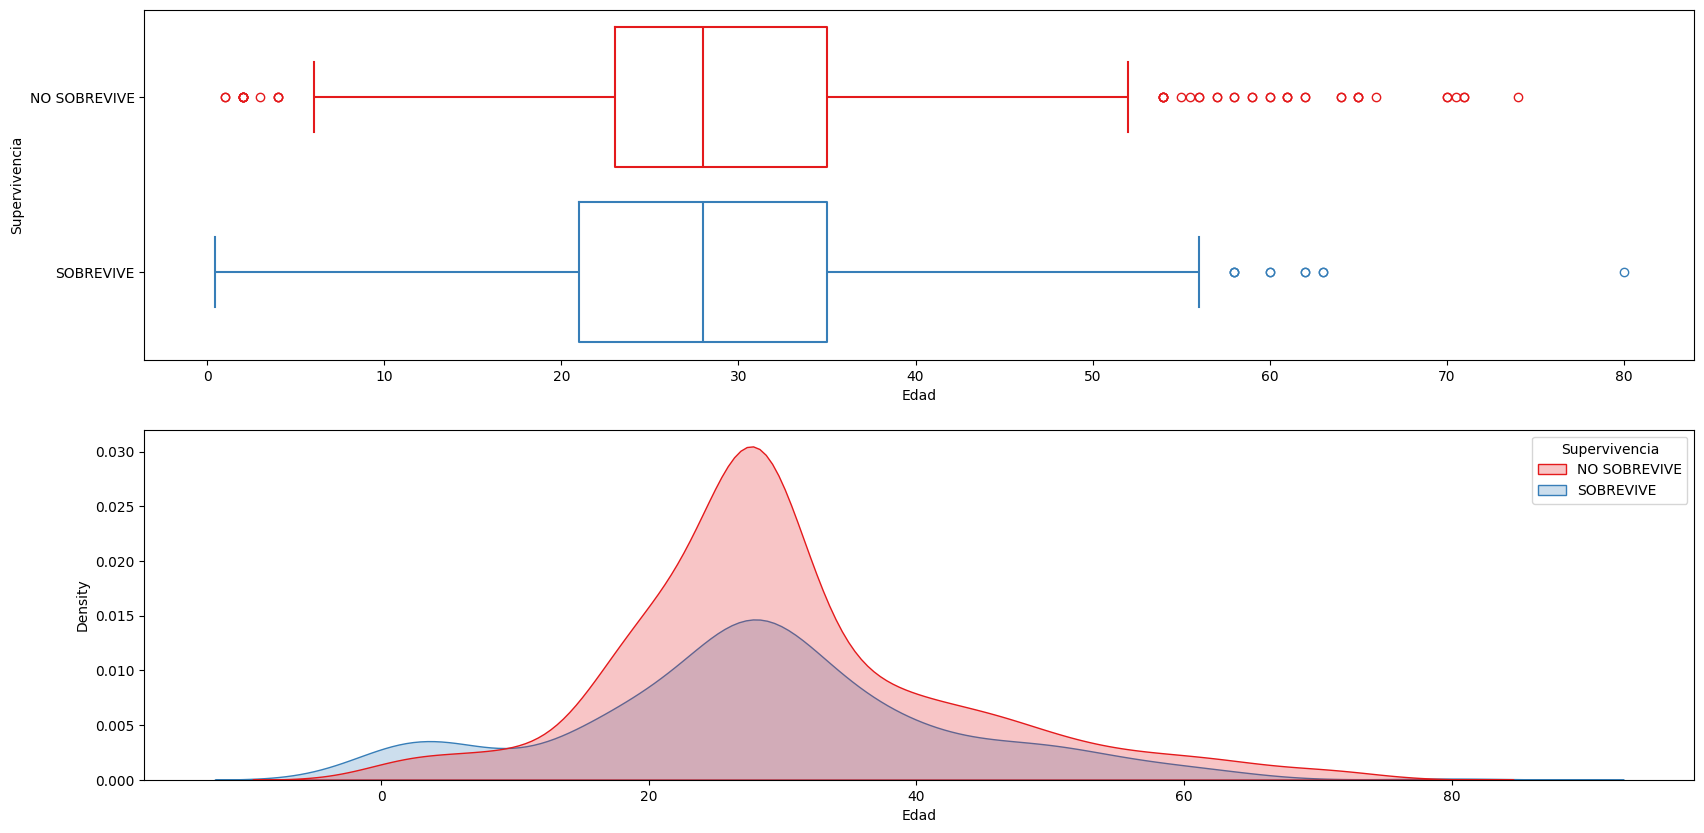

In [84]:
# Edad numérica vs Supervencia categórica

figure, axes = pyplot.subplots(2, 1, figsize=(20, 10))

seaborn.boxplot(x=edad, y=supervivencia, hue=supervivencia, fill=False, 
                palette="Set1", ax=axes[0])
seaborn.kdeplot(x=edad, hue=supervivencia, fill=True, 
                palette="Set1", ax=axes[1])

<Axes: xlabel='Sexo', ylabel='Supervivencia'>

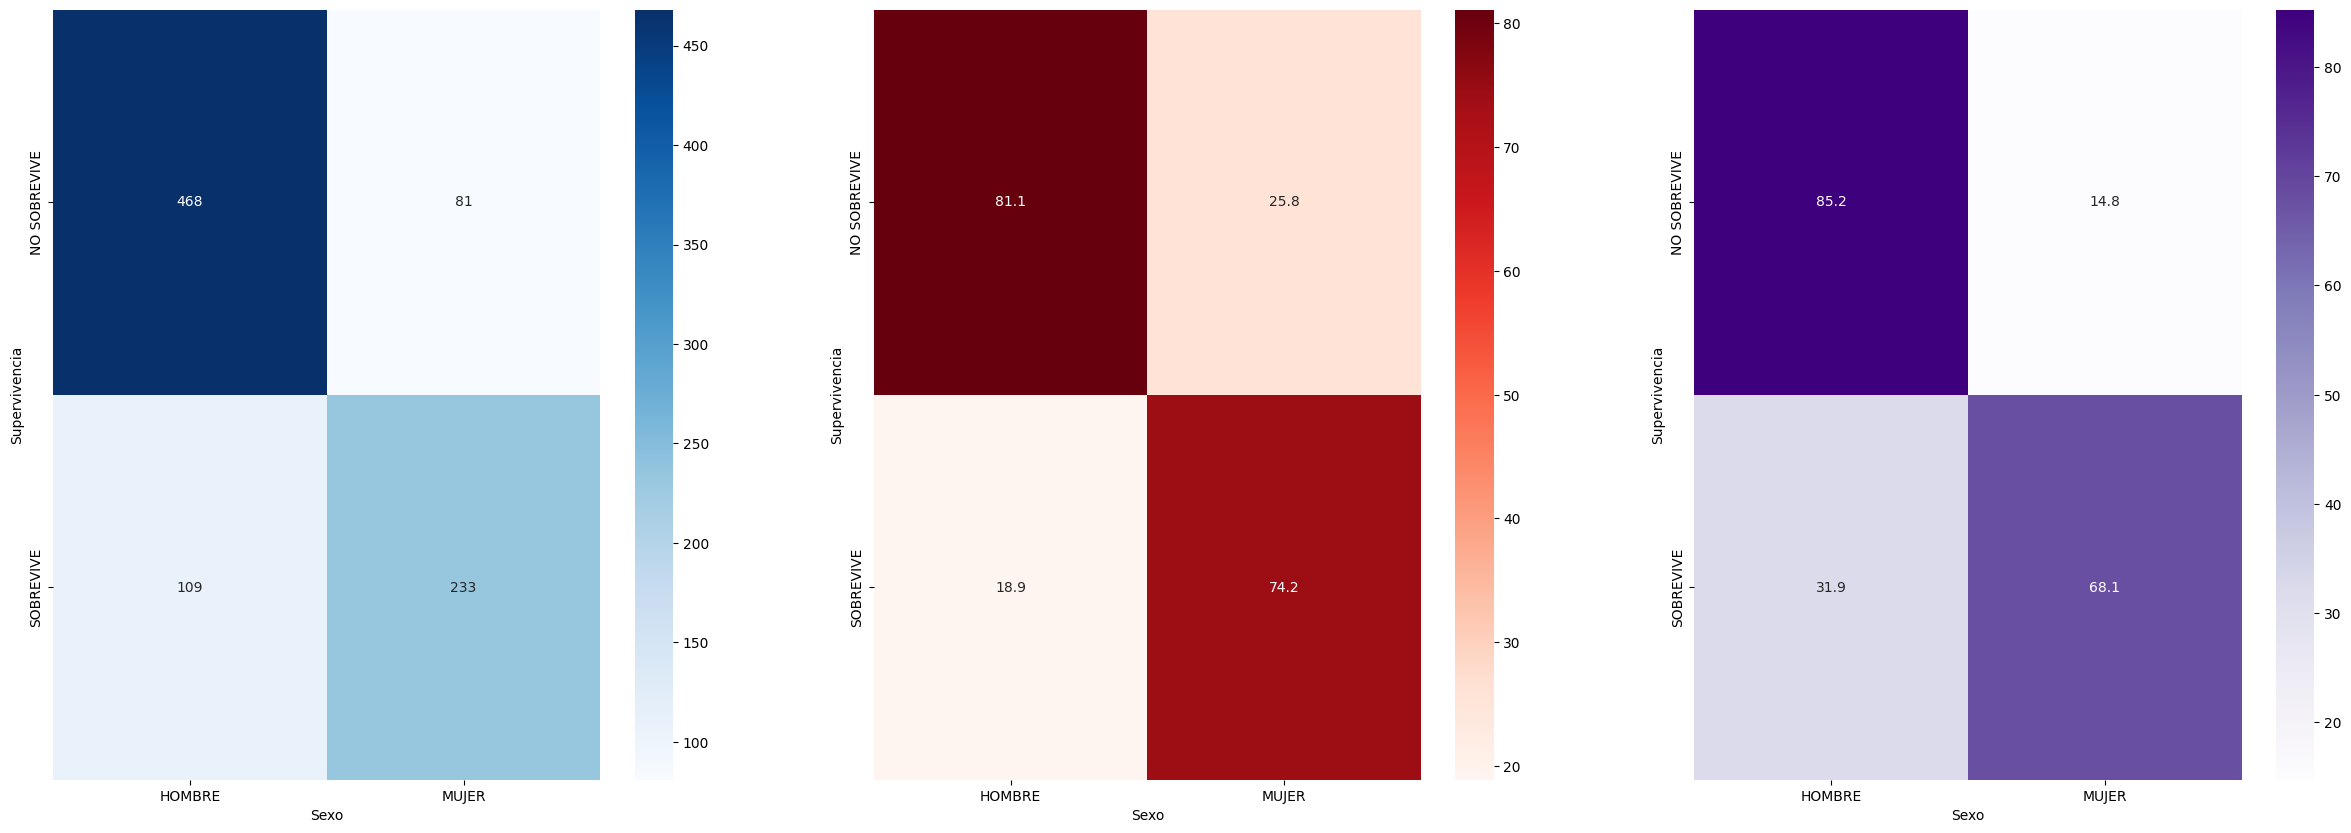

In [93]:
A = pandas.DataFrame({
    "Supervivencia": supervivencia,
    "Sexo": sexo
}).groupby(["Supervivencia", "Sexo"]).size().unstack()

B = A.divide(A.sum(axis=0), axis=1) * 100
C = A.divide(A.sum(axis=1), axis=0) * 100

figure, axes = pyplot.subplots(1, 3, figsize=(30, 10))

seaborn.heatmap(A, cmap="Blues", annot=True, fmt=".0f", ax=axes[0])
seaborn.heatmap(B, cmap="Reds", annot=True, fmt=".1f", ax=axes[1])
seaborn.heatmap(C, cmap="Purples", annot=True, fmt=".1f", ax=axes[2])

<Axes: xlabel='Familia', ylabel='Density'>

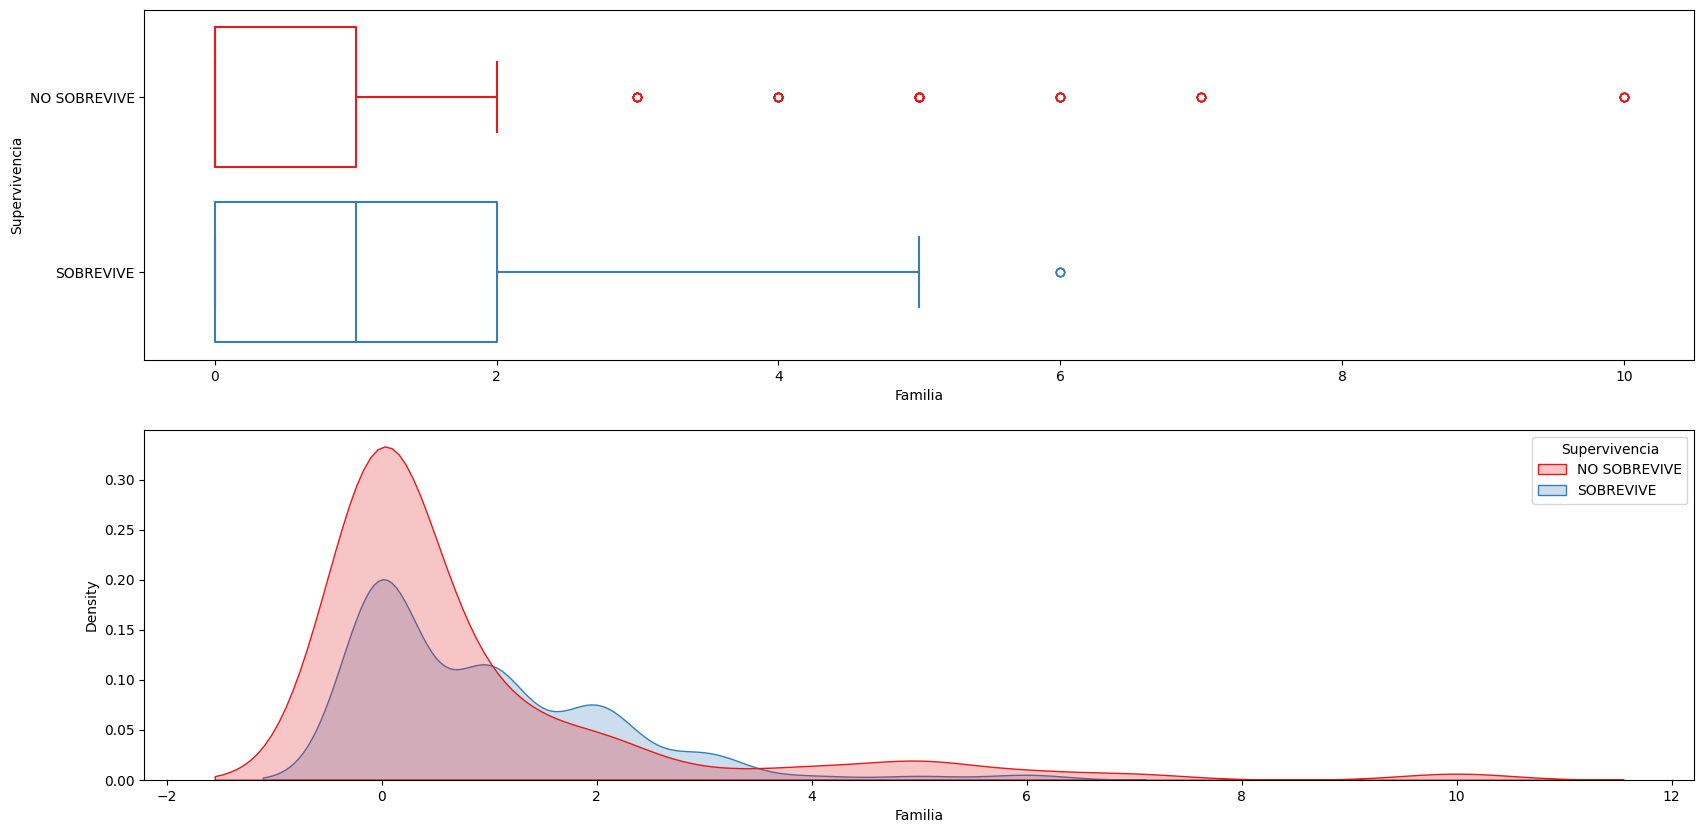

In [94]:
figure, axes = pyplot.subplots(2, 1, figsize=(20, 10))

seaborn.boxplot(x=familia, y=supervivencia, hue=supervivencia, fill=False, 
                palette="Set1", ax=axes[0])
seaborn.kdeplot(x=familia, hue=supervivencia, fill=True, 
                palette="Set1", ax=axes[1])

<Axes: xlabel='Tarifa', ylabel='Density'>

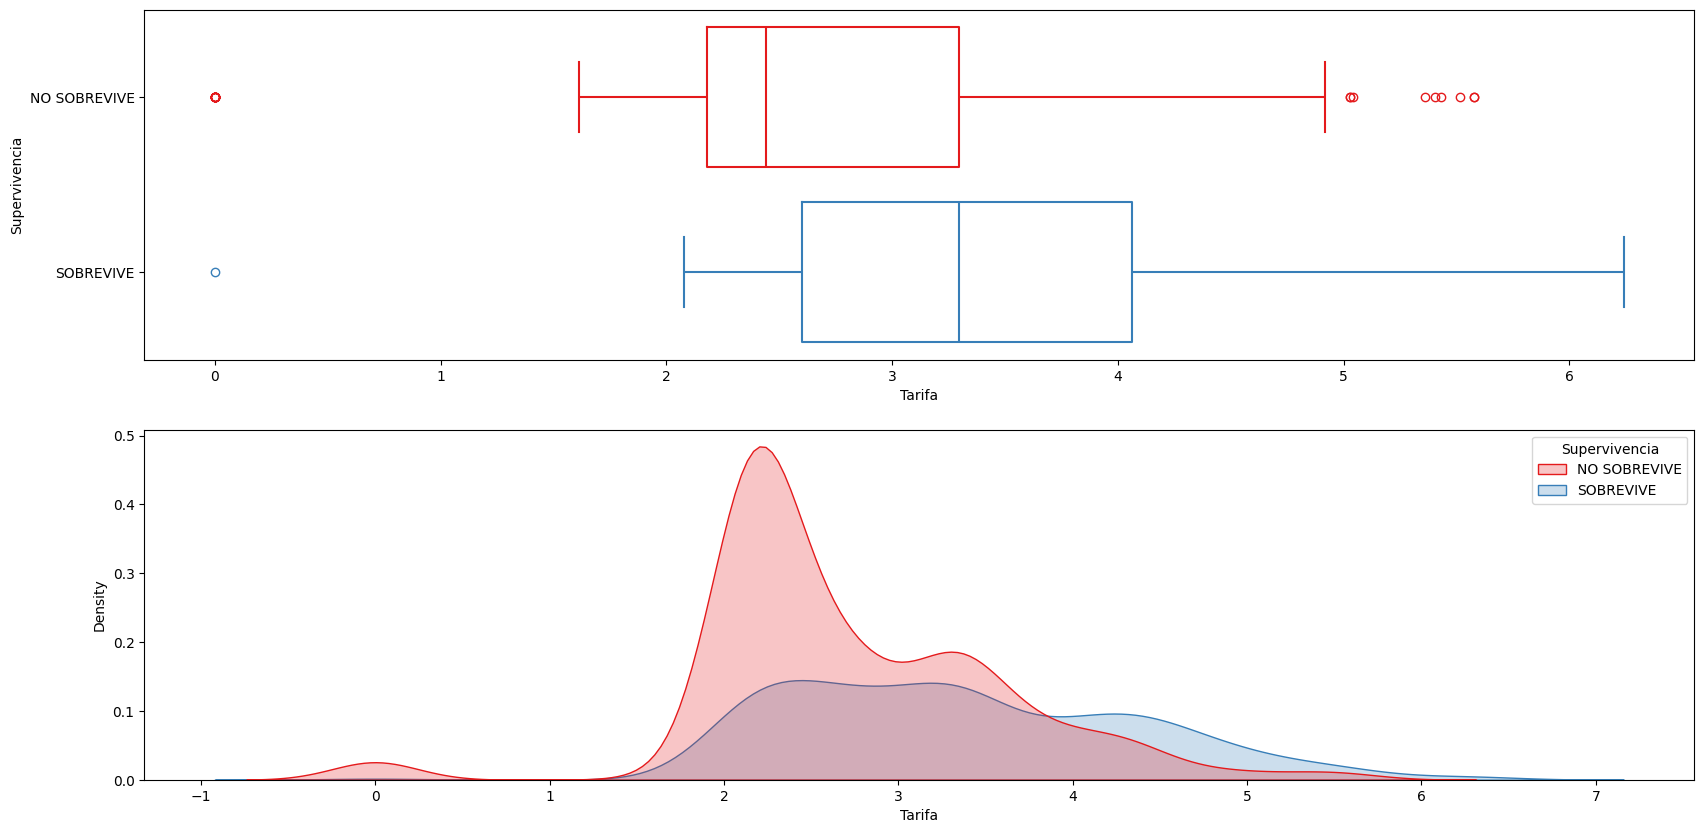

In [95]:
figure, axes = pyplot.subplots(2, 1, figsize=(20, 10))

seaborn.boxplot(x=tarifa, y=supervivencia, hue=supervivencia, fill=False, 
                palette="Set1", ax=axes[0])
seaborn.kdeplot(x=tarifa, hue=supervivencia, fill=True, 
                palette="Set1", ax=axes[1])

<Axes: xlabel='Cabina', ylabel='Supervivencia'>

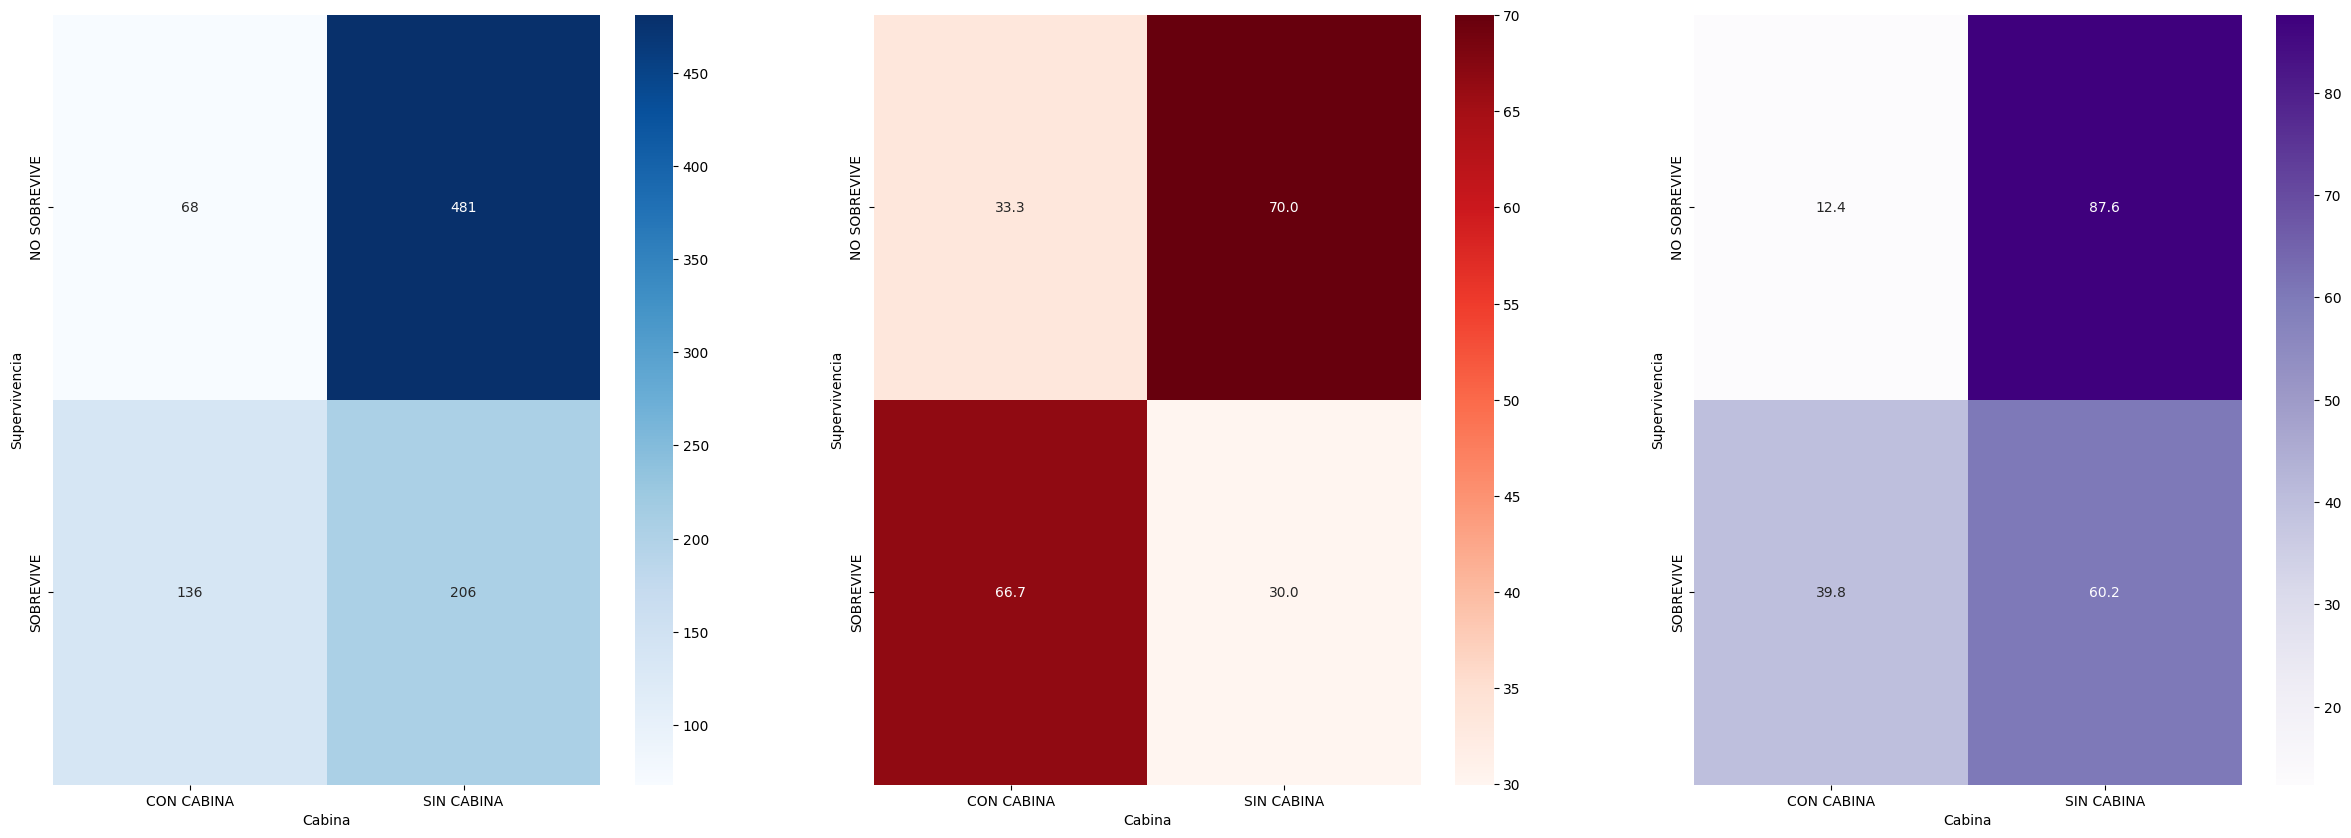

In [96]:
A = pandas.DataFrame({
    "Supervivencia": supervivencia,
    "Cabina": cabina
}).groupby(["Supervivencia", "Cabina"]).size().unstack()

B = A.divide(A.sum(axis=0), axis=1) * 100
C = A.divide(A.sum(axis=1), axis=0) * 100

figure, axes = pyplot.subplots(1, 3, figsize=(30, 10))

seaborn.heatmap(A, cmap="Blues", annot=True, fmt=".0f", ax=axes[0])
seaborn.heatmap(B, cmap="Reds", annot=True, fmt=".1f", ax=axes[1])
seaborn.heatmap(C, cmap="Purples", annot=True, fmt=".1f", ax=axes[2])

<Axes: xlabel='Embarcacion', ylabel='Supervivencia'>

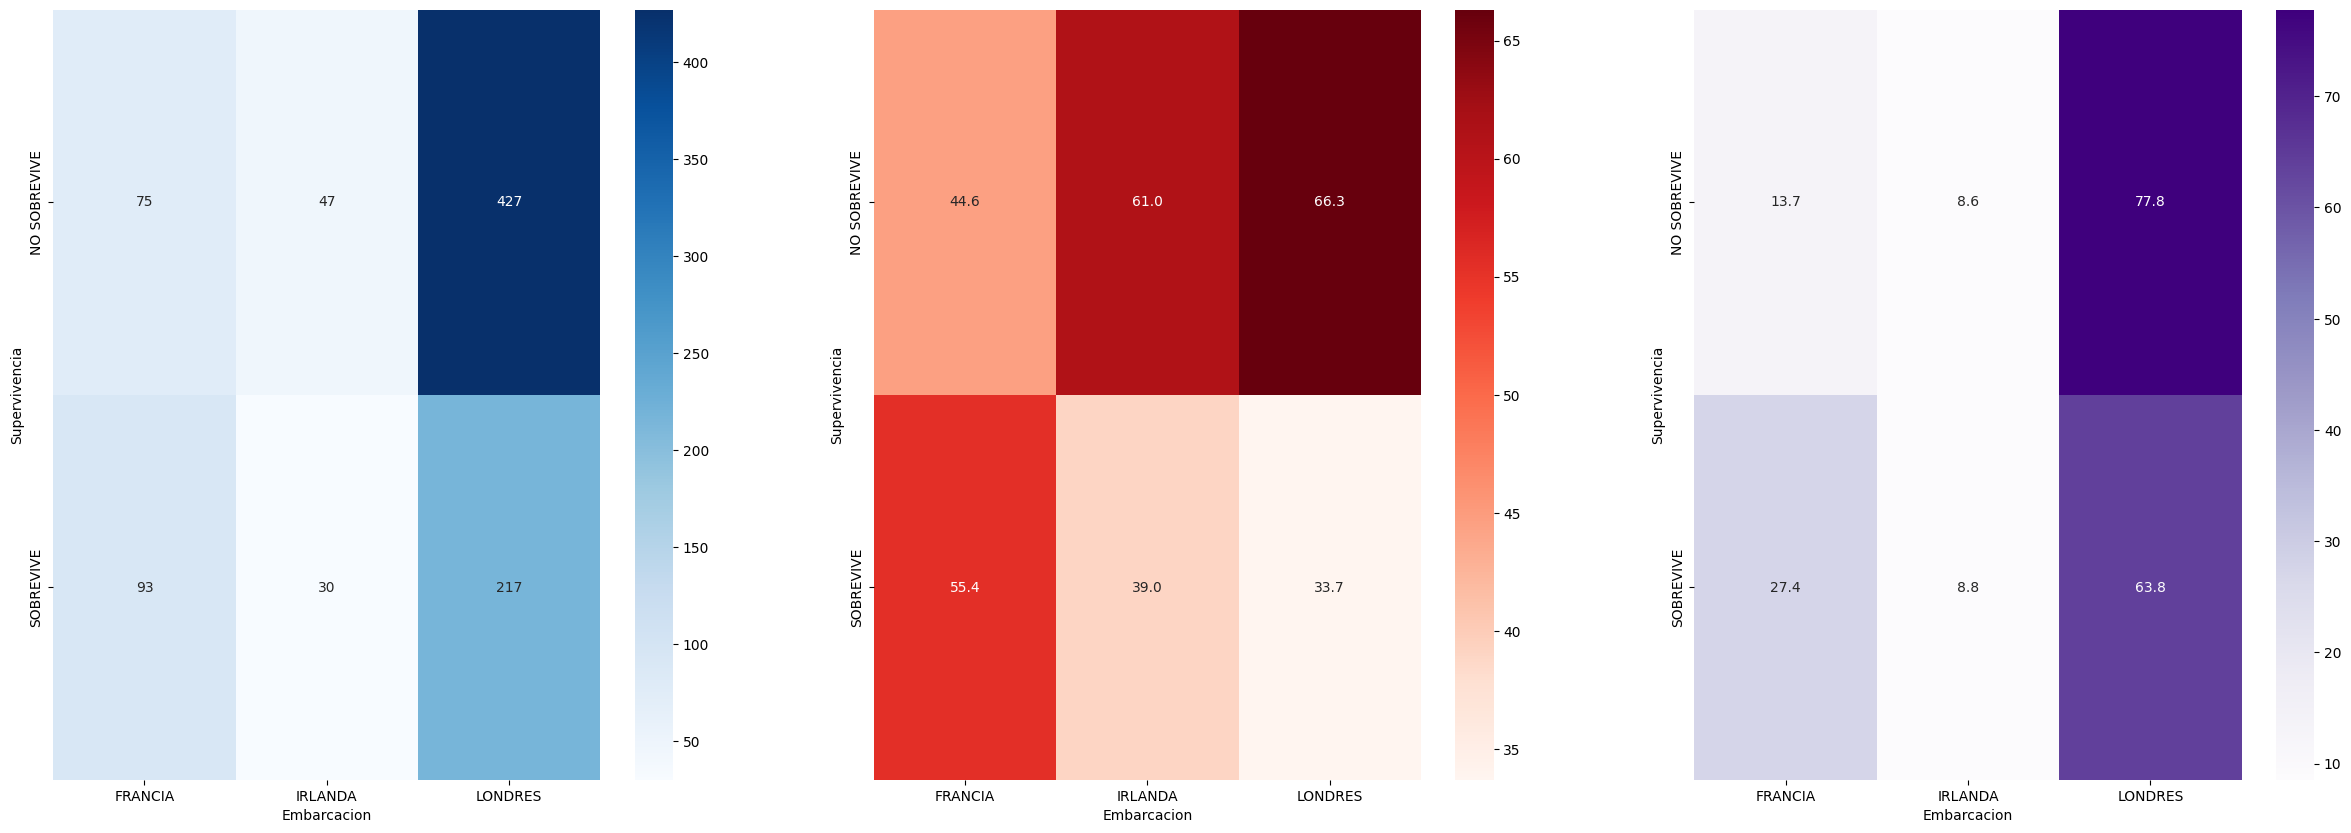

In [97]:
A = pandas.DataFrame({
    "Supervivencia": supervivencia,
    "Embarcacion": embarcacion
}).groupby(["Supervivencia", "Embarcacion"]).size().unstack()

B = A.divide(A.sum(axis=0), axis=1) * 100
C = A.divide(A.sum(axis=1), axis=0) * 100

figure, axes = pyplot.subplots(1, 3, figsize=(30, 10))

seaborn.heatmap(A, cmap="Blues", annot=True, fmt=".0f", ax=axes[0])
seaborn.heatmap(B, cmap="Reds", annot=True, fmt=".1f", ax=axes[1])
seaborn.heatmap(C, cmap="Purples", annot=True, fmt=".1f", ax=axes[2])

## Análisis Predictivo

### 1. Conjunto de Entrenamiento

> Separar X, Y

### 2. Aplicar el modelo de aprendizaje

> Red neuronal

1. **Red neuronal de respuesta lineal** - Aprender una respuesta abierta
2. **Red neuronal de respuesta logística** - Aprender una respuesta cerrada

### 3. Evaluación del aprendizaje

1. Error del aprendizaje
2. Métricas del aprendizaje
3. Aplicar una predicción

In [101]:
# Edad numérico
x1 = edad
# Sexo categórico (2 dummies)
x2 = (sexo == "MUJER").astype(int) # La base es ser hombre
# Familia numérico
x3 = familia
# Tarifa numérico
x4 = tarifa
# Cabina categórico (2 dummies)
x5 = (cabina == "CON CABINA").astype(int) # La base es no tener cabina
# Embarcación categórico (3 dummies)
x6 = (embarcacion == "IRLANDA").astype(int) # La base es embarcar en londres
x6.name = "Embarca Irlanda"
x7 = (embarcacion == "FRANCIA").astype(int) # La base es embarcar en londres
x7.name = "Embarca Francia"

X = pandas.DataFrame([x1, x2, x3, x4, x5, x6, x7]).T

X

,Edad,Sexo,Familia,Tarifa,Cabina,Embarca Irlanda,Embarca Francia
0,22.0,0.0,1.0,2.110213,0.0,0.0,0.0
1,38.0,1.0,1.0,4.280593,1.0,0.0,1.0
2,26.0,1.0,0.0,2.188856,0.0,0.0,0.0
3,35.0,1.0,1.0,3.990834,1.0,0.0,0.0
4,35.0,0.0,0.0,2.202765,0.0,0.0,0.0
...,...,...,...,...,...,...,...
886,27.0,0.0,0.0,2.639057,0.0,0.0,0.0
887,19.0,1.0,0.0,3.433987,1.0,0.0,0.0
888,28.0,1.0,3.0,3.196630,0.0,0.0,0.0
889,26.0,0.0,0.0,3.433987,1.0,0.0,1.0


In [102]:
y1 = (supervivencia == "SOBREVIVE").astype(int)

y1

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Supervivencia, Length: 891, dtype: int64

In [ ]:
! python -V

In [ ]:
! python -m pip install tensorflow keras

In [103]:
import keras

In [ ]:
# Red neuronal de 1 sola neurona / ML Logístico
modelo = keras.Sequential([
    keras.Input(shape=(7,)),
    keras.layers.Dense(64, activation="relu"), # 64 neuronas primera capa
    keras.layers.Dense(64, activation="relu"), # 64 neuronas segunda capa
    keras.layers.Dense(1, activation="sigmoid")
])

modelo.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

modelo.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8 (32.00 B)

 Trainable params: 8 (32.00 B)

 Non-trainable params: 0 (0.00 B)

In [117]:
historial = modelo.fit(X, y1, epochs=500)

Epoch 1/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 863us/step - accuracy: 0.6330 - loss: 6.4923
Epoch 2/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 800us/step - accuracy: 0.6351 - loss: 5.9655
Epoch 3/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 839us/step - accuracy: 0.6419 - loss: 5.4060
Epoch 4/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 814us/step - accuracy: 0.6326 - loss: 5.2525
Epoch 5/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 968us/step - accuracy: 0.6270 - loss: 5.5469
Epoch 6/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6380 - loss: 4.6451 
Epoch 7/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6283 - loss: 4.4883 
Epoch 8/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 882us/step - accuracy: 0.6518 - loss: 3.9133
Epoch 9/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 935us/step - accuracy: 0.6426 - loss: 3.7066
Epoch 10/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 973us/step - accuracy: 0.6206 - loss: 3.4903
Epoch 11/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 955us/step - accuracy: 0.6438 - loss: 3.0031
Epoch 12/500
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 

<Axes: >

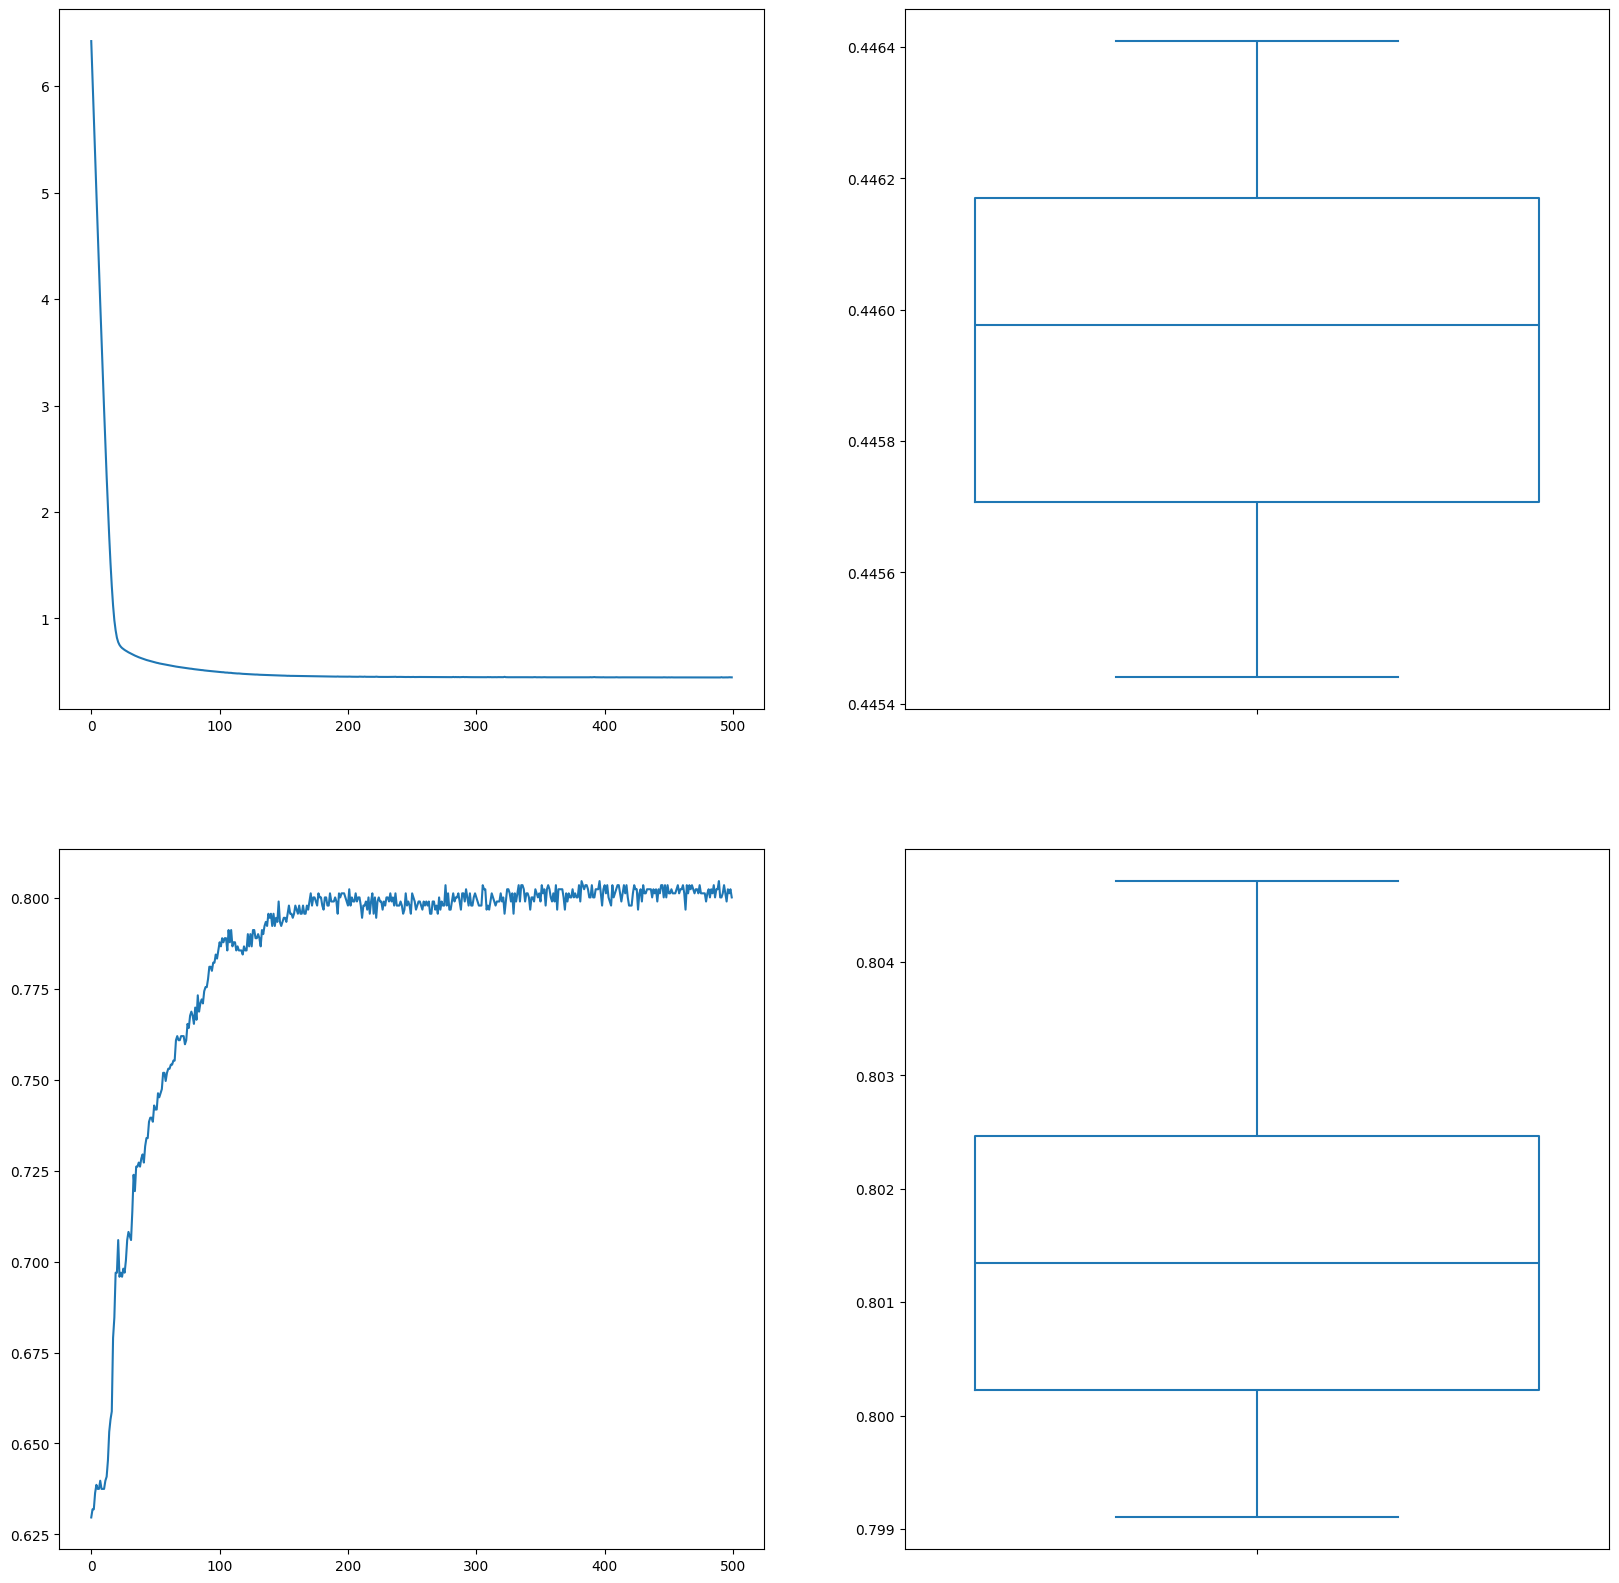

In [118]:
epocas = historial.epoch
error = historial.history["loss"]
precision = historial.history["accuracy"]

figure, axes = pyplot.subplots(2, 2, figsize=(20, 20))

seaborn.lineplot(x=epocas, y=error, ax=axes[0][0])
seaborn.boxplot(y=error[-20:], showfliers=False, fill=False, ax=axes[0][1])
seaborn.lineplot(x=epocas, y=precision, ax=axes[1][0])
seaborn.boxplot(y=precision[-20:], showfliers=False, fill=False, ax=axes[1][1])

In [119]:
modelo.save("nn_titanic_1.keras")

In [120]:
modelo = keras.models.load_model("nn_titanic_1.keras")

modelo.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26 (108.00 B)

 Trainable params: 8 (32.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 18 (76.00 B)

In [121]:
modelo.predict(numpy.array([
    [23, 1, 0, numpy.log1p(28), 1, 0, 0], # 23 años | MUJER | 0-FAMILIA | 28 libras | CON CABINA | NO IRLANDA | NO FRANCIA
    [23, 0, 0, numpy.log1p(28), 1, 0, 0], # 23 años | MUJER | 0-FAMILIA | 28 libras | CON CABINA | NO IRLANDA | NO FRANCIA
]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


array([[0.94746023],
       [0.5578794 ]], dtype=float32)